In [1]:
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import pandas as pd

In [2]:
ds = xr.open_dataset('aerosols_species.nc')
ds

<xarray.Dataset> Size: 83MB
Dimensions:     (valid_time: 1827, latitude: 43, longitude: 44)
Coordinates:
  * valid_time  (valid_time) datetime64[ns] 15kB 2020-01-01 ... 2024-12-31
  * latitude    (latitude) float64 344B 27.0 26.25 25.5 ... -3.0 -3.75 -4.5
  * longitude   (longitude) float64 352B -17.5 -16.75 -16.0 ... 13.25 14.0 14.75
Data variables:
    bcaod550    (valid_time, latitude, longitude) float32 14MB ...
    duaod550    (valid_time, latitude, longitude) float32 14MB ...
    omaod550    (valid_time, latitude, longitude) float32 14MB ...
    ssaod550    (valid_time, latitude, longitude) float32 14MB ...
    suaod550    (valid_time, latitude, longitude) float32 14MB ...
    aod550      (valid_time, latitude, longitude) float32 14MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2025-12-23T04:52 GRIB to CDM+CF via cfgrib-0.9.1...

In [12]:
# Extract aerosol variables
bc = ds["bcaod550"]     # Black Carbon
dust = ds["duaod550"]   # Dust
om = ds["omaod550"]     # Organic Matter
ss = ds["ssaod550"]     # Sea Salt
sul = ds["suaod550"]    # Sulphate

In [13]:
bc_monthly = bc.resample(valid_time="MS").mean()
dust_monthly = dust.resample(valid_time="MS").mean()
om_monthly = om.resample(valid_time="MS").mean()
ss_monthly = ss.resample(valid_time="MS").mean()
sul_monthly = sul.resample(valid_time="MS").mean()

In [14]:
bc_ts = bc_monthly.mean(dim=["latitude", "longitude"])
dust_ts = dust_monthly.mean(dim=["latitude", "longitude"])
om_ts = om_monthly.mean(dim=["latitude", "longitude"])
ss_ts = ss_monthly.mean(dim=["latitude", "longitude"])
sul_ts = sul_monthly.mean(dim=["latitude", "longitude"])

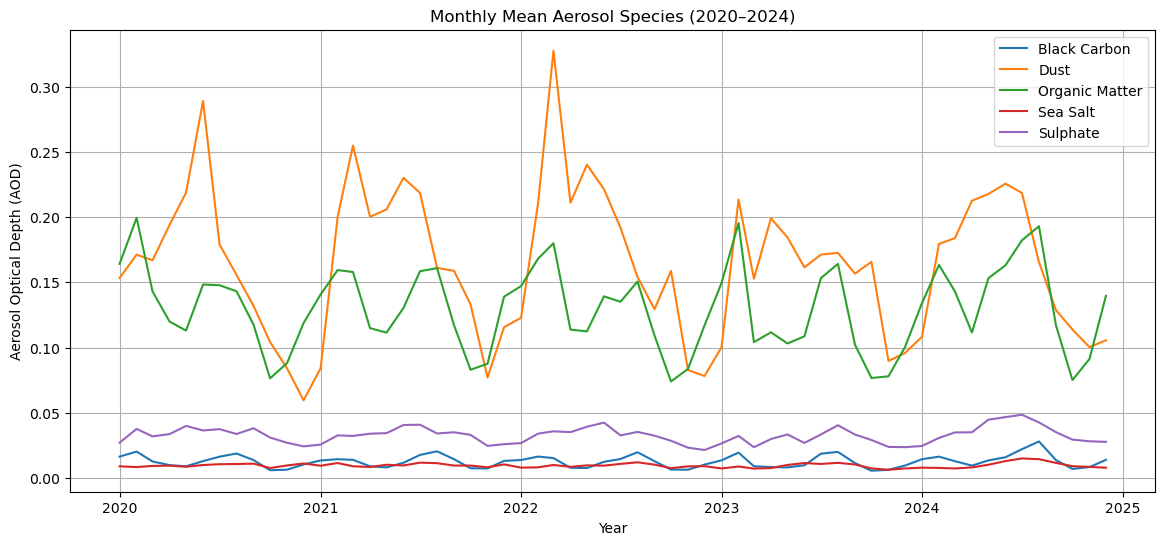

In [15]:
plt.figure(figsize=(14,6))

plt.plot(bc_ts.valid_time, bc_ts, label="Black Carbon")
plt.plot(dust_ts.valid_time, dust_ts, label="Dust")
plt.plot(om_ts.valid_time, om_ts, label="Organic Matter")
plt.plot(ss_ts.valid_time, ss_ts, label="Sea Salt")
plt.plot(sul_ts.valid_time, sul_ts, label="Sulphate")

plt.title("Monthly Mean Aerosol Species (2020–2024)")
plt.xlabel("Year")
plt.ylabel("Aerosol Optical Depth (AOD)")
plt.legend()
plt.grid(True)

plt.show()

In [18]:
summary = pd.DataFrame({
    "Mean": [
        float(bc.mean()),
        float(dust.mean()),
        float(om.mean()),
        float(ss.mean()),
        float(sul.mean())
    ],
    "Maximum": [
        float(bc.max()),
        float(dust.max()),
        float(om.max()),
        float(ss.max()),
        float(sul.max())
    ],
    "Minimum": [
        float(bc.min()),
        float(dust.min()),
        float(om.min()),
        float(ss.min()),
        float(sul.min())
    ],
    "Standard Deviation": [
        float(bc.std()),
        float(dust.std()),
        float(om.std()),
        float(ss.std()),
        float(sul.std())
    ]
},
index=[
    "Black Carbon",
    "Dust",
    "Organic Matter",
    "Sea Salt",
    "Sulphate"
])

summary

,Mean,Maximum,Minimum,Standard Deviation
Black Carbon,0.012603,0.486001,0.000035,0.015246
Dust,0.164204,2.712680,0.000013,0.186885
Organic Matter,0.129505,3.901727,0.000277,0.133659
Sea Salt,0.009467,0.161294,0.000081,0.010554
Sulphate,0.032629,0.644174,0.000047,0.025002


In [19]:
# Black Carbon
bc_seasonal = bc_monthly.groupby("valid_time.season").mean()

# Dust
dust_seasonal = dust_monthly.groupby("valid_time.season").mean()

# Organic Matter
om_seasonal = om_monthly.groupby("valid_time.season").mean()

# Sea Salt
ss_seasonal = ss_monthly.groupby("valid_time.season").mean()

# Sulphate
sul_seasonal = sul_monthly.groupby("valid_time.season").mean()

In [22]:
bc_season_mean = bc_seasonal.mean(dim=["latitude", "longitude"])
dust_season_mean = dust_seasonal.mean(dim=["latitude", "longitude"])
om_season_mean = om_seasonal.mean(dim=["latitude", "longitude"])
ss_season_mean = ss_seasonal.mean(dim=["latitude", "longitude"])
sul_season_mean = sul_seasonal.mean(dim=["latitude", "longitude"])

In [23]:
season_table = pd.DataFrame({
    "Black Carbon": bc_season_mean.values,
    "Dust": dust_season_mean.values,
    "Organic Matter": om_season_mean.values,
    "Sea Salt": ss_season_mean.values,
    "Sulphate": sul_season_mean.values
},
index=bc_season_mean.season.values)

season_table

,Black Carbon,Dust,Organic Matter,Sea Salt,Sulphate
DJF,0.014282,0.133214,0.149078,0.008694,0.027966
JJA,0.017170,0.194448,0.151903,0.011403,0.038069
MAM,0.010203,0.211405,0.126201,0.008799,0.034440
SON,0.008782,0.120981,0.091738,0.008929,0.030057


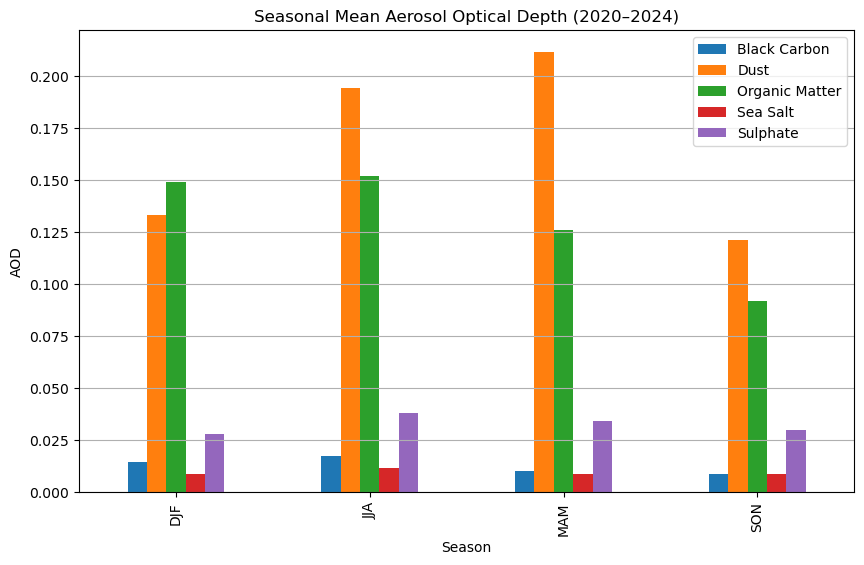

In [24]:
season_table.plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Seasonal Mean Aerosol Optical Depth (2020–2024)")
plt.xlabel("Season")
plt.ylabel("AOD")
plt.grid(axis="y")

plt.show()

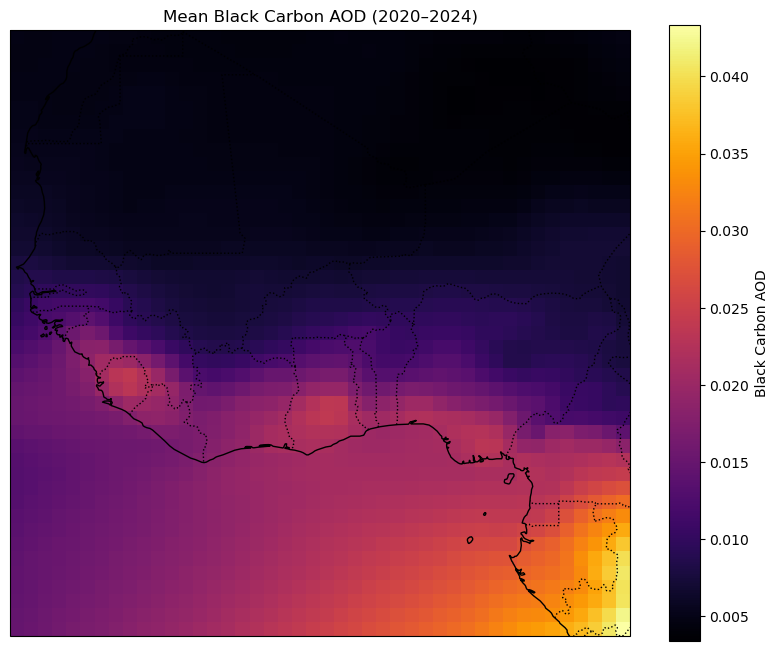

In [61]:
annual_bc = bc.mean(dim="valid_time")

plt.figure(figsize=(10,8))

ax = plt.axes(projection=ccrs.PlateCarree())

annual_bc.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="inferno",
    cbar_kwargs={"label": "Black Carbon AOD"}
)

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)

plt.title("Mean Black Carbon AOD (2020–2024)")

plt.show()

Inferno' is not a valid value for cmap; supported values are 'Accent', 'Accent_r', 'Blues', 'Blues_r', 'BrBG', 'BrBG_r', 'BuGn', 'BuGn_r', 'BuPu', 'BuPu_r', 'CMRmap', 'CMRmap_r', 'Dark2', 'Dark2_r', 'GnBu', 'GnBu_r', 'Grays', 'Grays_r', 'Greens', 'Greens_r', 'Greys', 'Greys_r', 'OrRd', 'OrRd_r', 'Oranges', 'Oranges_r', 'PRGn', 'PRGn_r', 'Paired', 'Paired_r', 'Pastel1', 'Pastel1_r', 'Pastel2', 'Pastel2_r', 'PiYG', 'PiYG_r', 'PuBu', 'PuBuGn', 'PuBuGn_r', 'PuBu_r', 'PuOr', 'PuOr_r', 'PuRd', 'PuRd_r', 'Purples', 'Purples_r', 'RdBu', 'RdBu_r', 'RdGy', 'RdGy_r', 'RdPu', 'RdPu_r', 'RdYlBu', 'RdYlBu_r', 'RdYlGn', 'RdYlGn_r', 'Reds', 'Reds_r', 'Set1', 'Set1_r', 'Set2', 'Set2_r', 'Set3', 'Set3_r', 'Spectral', 'Spectral_r', 'Wistia', 'Wistia_r', 'YlGn', 'YlGnBu', 'YlGnBu_r', 'YlGn_r', 'YlOrBr', 'YlOrBr_r', 'YlOrRd', 'YlOrRd_r', 'afmhot', 'afmhot_r', 'autumn', 'autumn_r', 'berlin', 'berlin_r', 'binary', 'binary_r', 'bone', 'bone_r', 'brg', 'brg_r', 'bwr', 'bwr_r', 'cividis', 'cividis_r', 'cool', 'cool_r', 'coolwarm', 'coolwarm_r', 'copper', 'copper_r', 'cubehelix', 'cubehelix_r', 'flag', 'flag_r', 'gist_earth', 'gist_earth_r', 'gist_gray', 'gist_gray_r', 'gist_grey', 'gist_grey_r', 'gist_heat', 'gist_heat_r', 'gist_ncar', 'gist_ncar_r', 'gist_rainbow', 'gist_rainbow_r', 'gist_stern', 'gist_stern_r', 'gist_yarg', 'gist_yarg_r', 'gist_yerg', 'gist_yerg_r', 'gnuplot', 'gnuplot2', 'gnuplot2_r', 'gnuplot_r', 'gray', 'gray_r', 'grey', 'grey_r', 'hot', 'hot_r', 'hsv', 'hsv_r', 'inferno', 'inferno_r', 'jet', 'jet_r', 'magma', 'magma_r', 'managua', 'managua_r', 'nipy_spectral', 'nipy_spectral_r', 'ocean', 'ocean_r', 'pink', 'pink_r', 'plasma', 'plasma_r', 'prism', 'prism_r', 'rainbow', 'rainbow_r', 'seismic', 'seismic_r', 'spring', 'spring_r', 'summer', 'summer_r', 'tab10', 'tab10_r', 'tab20', 'tab20_r', 'tab20b', 'tab20b_r', 'tab20c', 'tab20c_r', 'terrain', 'terrain_r', 'turbo', 'turbo_r', 'twilight', 'twilight_r', 'twilight_shifted', 'twilight_shifted_r', 'vanimo', 'vanimo_r', 'viridis', 'viridis_r', 'winter', 'winter_r'

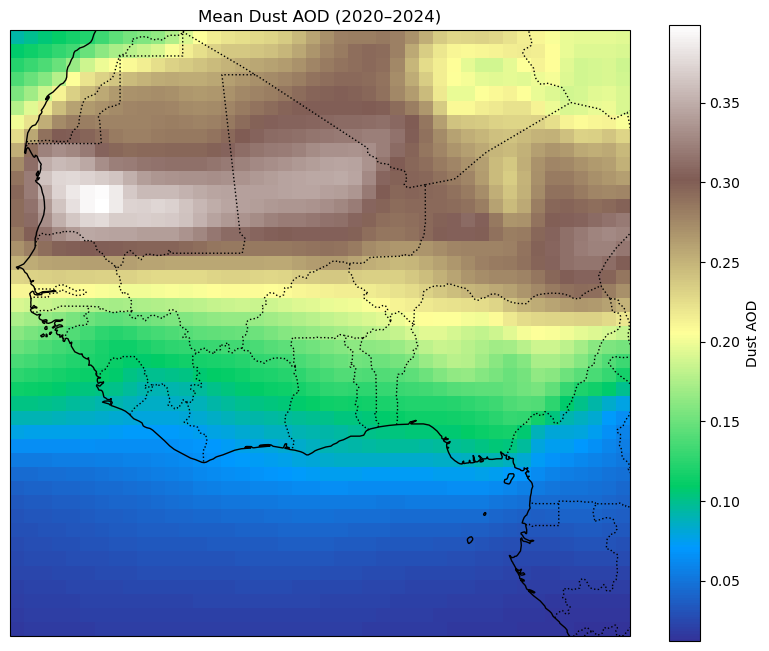

In [64]:
annual_dust = dust.mean(dim="valid_time")

plt.figure(figsize=(10,8))

ax = plt.axes(projection=ccrs.PlateCarree())

annual_dust.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="terrain",
    cbar_kwargs={"label": "Dust AOD"}
)

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
#ax.add_feature(cfeature.RIVERS)
plt.title("Mean Dust AOD (2020–2024)")

plt.show()

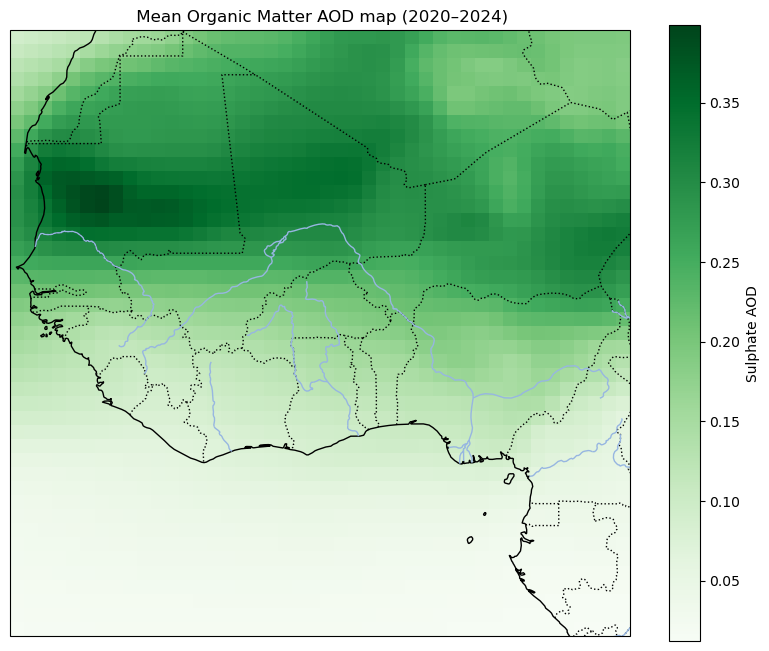

In [80]:
annual_om = om.mean(dim="valid_time")

plt.figure(figsize=(10,8))

ax = plt.axes(projection=ccrs.PlateCarree())

annual_dust.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="Greens",
    cbar_kwargs={"label": "Sulphate AOD"}
)

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.RIVERS)
plt.title(" Mean Organic Matter AOD map (2020–2024)")

plt.show()

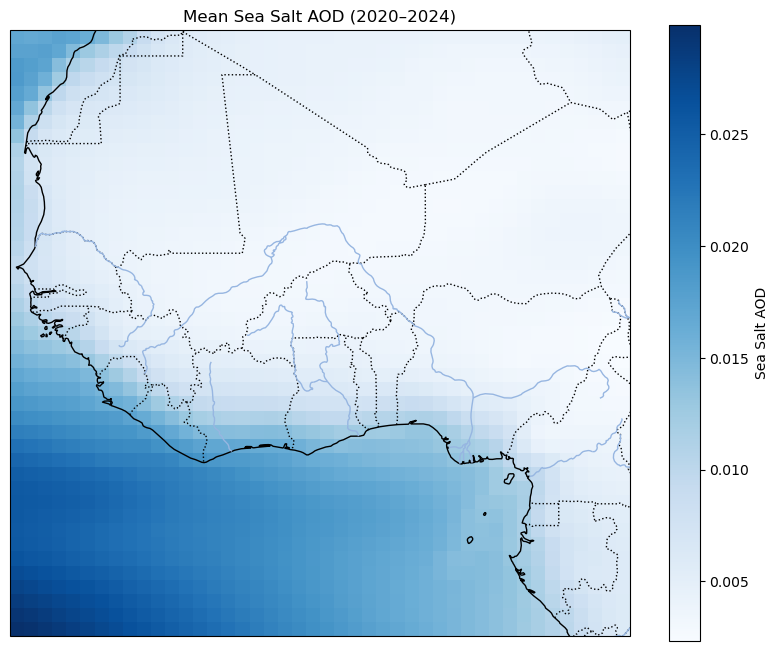

In [67]:
annual_ss = ss.mean(dim="valid_time")

plt.figure(figsize=(10,8))

ax = plt.axes(projection=ccrs.PlateCarree())

annual_ss.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="Blues",
    cbar_kwargs={"label": "Sea Salt AOD"}
)

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.RIVERS)
plt.title("Mean Sea Salt AOD (2020–2024)")

plt.show()

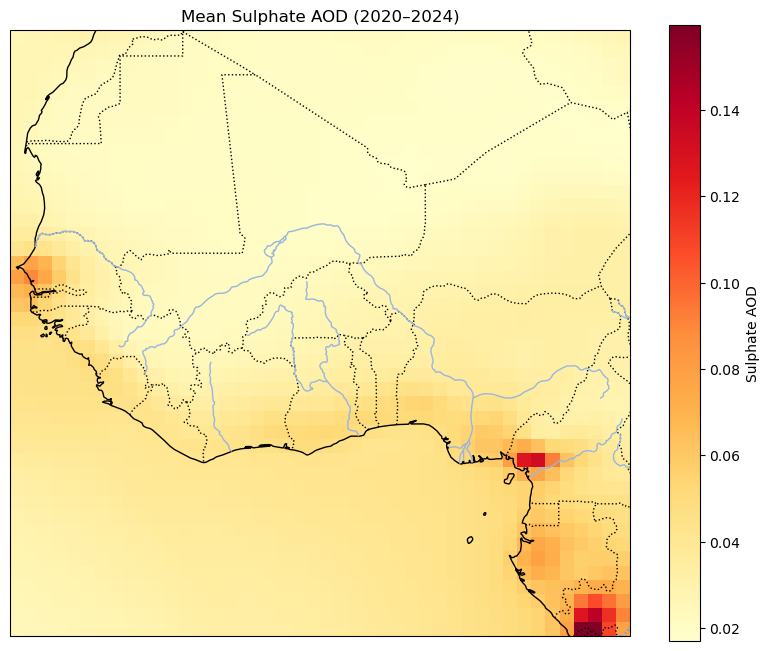

In [60]:
annual_sul = sul.mean(dim="valid_time")

plt.figure(figsize=(10,8))

ax = plt.axes(projection=ccrs.PlateCarree())

annual_sul.plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    cmap="YlOrRd",
    cbar_kwargs={"label": "Sulphate AOD"}
)

ax.coastlines()
ax.add_feature(cfeature.BORDERS, linestyle=":")
ax.add_feature(cfeature.LAND)
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.RIVERS)
plt.title("Mean Sulphate AOD (2020–2024)")

plt.show()

In [68]:
# Annual means
bc_annual = bc.resample(valid_time="YS").mean()
dust_annual = dust.resample(valid_time="YS").mean()
om_annual = om.resample(valid_time="YS").mean()
ss_annual = ss.resample(valid_time="YS").mean()
sul_annual = sul.resample(valid_time="YS").mean()

In [69]:
bc_year = bc_annual.mean(dim=["latitude", "longitude"])
dust_year = dust_annual.mean(dim=["latitude", "longitude"])
om_year = om_annual.mean(dim=["latitude", "longitude"])
ss_year = ss_annual.mean(dim=["latitude", "longitude"])
sul_year = sul_annual.mean(dim=["latitude", "longitude"])

In [70]:
annual_table = pd.DataFrame({
    "Year": bc_year.valid_time.dt.year.values,
    "Black Carbon": bc_year.values,
    "Dust": dust_year.values,
    "Organic Matter": om_year.values,
    "Sea Salt": ss_year.values,
    "Sulphate": sul_year.values
})

annual_table

,Year,Black Carbon,Dust,Organic Matter,Sea Salt,Sulphate
0,2020,0.012598,0.158751,0.131401,0.009510,0.033072
1,2021,0.012491,0.169778,0.130010,0.009803,0.032671
2,2022,0.011854,0.177343,0.127354,0.009277,0.032157
3,2023,0.011505,0.154845,0.120182,0.008747,0.029594
4,2024,0.014556,0.163231,0.138943,0.009963,0.035618


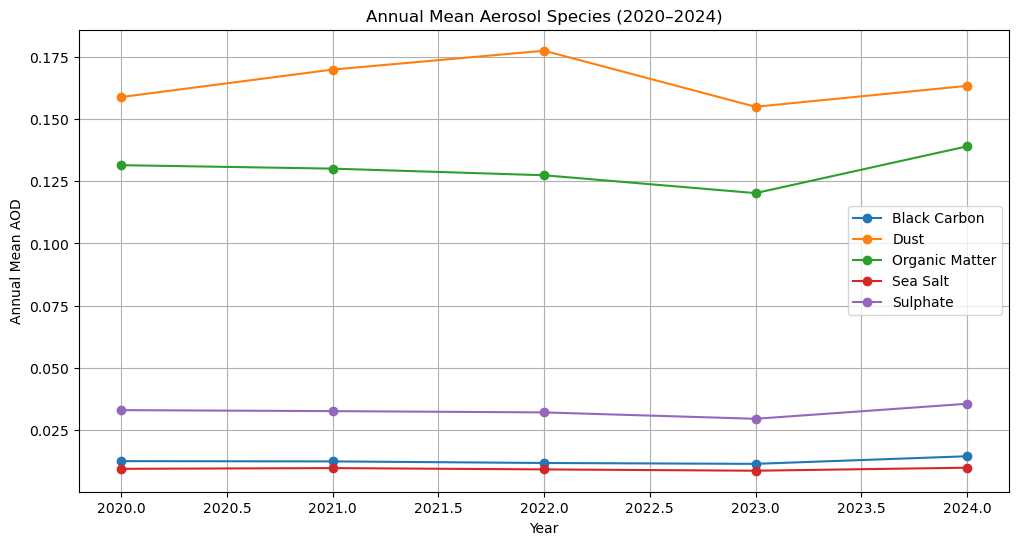

In [71]:
plt.figure(figsize=(12,6))

plt.plot(annual_table["Year"], annual_table["Black Carbon"], marker='o', label="Black Carbon")
plt.plot(annual_table["Year"], annual_table["Dust"], marker='o', label="Dust")
plt.plot(annual_table["Year"], annual_table["Organic Matter"], marker='o', label="Organic Matter")
plt.plot(annual_table["Year"], annual_table["Sea Salt"], marker='o', label="Sea Salt")
plt.plot(annual_table["Year"], annual_table["Sulphate"], marker='o', label="Sulphate")

plt.xlabel("Year")
plt.ylabel("Annual Mean AOD")
plt.title("Annual Mean Aerosol Species (2020–2024)")
plt.legend()
plt.grid(True)

plt.show()

In [72]:
years = annual_table["Year"]

bc_slope = np.polyfit(years, annual_table["Black Carbon"], 1)[0]
dust_slope = np.polyfit(years, annual_table["Dust"], 1)[0]
om_slope = np.polyfit(years, annual_table["Organic Matter"], 1)[0]
ss_slope = np.polyfit(years, annual_table["Sea Salt"], 1)[0]
sul_slope = np.polyfit(years, annual_table["Sulphate"], 1)[0]

In [73]:
trend_table = pd.DataFrame({
    "Aerosol Species": [
        "Black Carbon",
        "Dust",
        "Organic Matter",
        "Sea Salt",
        "Sulphate"
    ],
    "Trend Slope": [
        bc_slope,
        dust_slope,
        om_slope,
        ss_slope,
        sul_slope
    ]
})

print(trend_table)

  Aerosol Species  Trend Slope
0    Black Carbon     0.000293
1            Dust    -0.000597
2  Organic Matter     0.000526
3        Sea Salt    -0.000015
4        Sulphate     0.000202


In [79]:
summary.to_csv("summary_statistics.csv", index=True)
season_table.to_csv("seasonal_means.csv")
annual_table.to_csv("annual_means.csv", index=False)
trend_table.to_csv("trend_slopes.csv", index=False)